# Assignment

Implement the following Neural Architecture Search methods using this framework:

* Random Search
* Random Sample
* Bayesian Optimisation (put some thoughts how to represent information for the surrogate
model and how to define an acquition function)
* Succesive Halving
* An iteration-based learning curve method (see, e.g., the Power-law version of [1]).

Compare the performance of these methods using some reasonable standards (e.g., give
them the same budget) on various pre-computed datasets.

Setting up NAS system

In [38]:
import os
import csv
import random
import time
import json
import pickle

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from nats_bench import create

SEARCH_SPACES = {'tss': 'NATS-Bench topology (TSS)'}
SEARCH_SPACE = 'tss'

FAST_MODE = True
BENCH_PATH = "data/NATS-tss-v1_0-3ffb9-simple"

DATASETS = ['cifar10', 'ImageNet16-120']


if not os.path.exists(BENCH_PATH):
    raise FileNotFoundError('Benchmark not found at {}. See section 1.'.format(BENCH_PATH))

api = create(BENCH_PATH, SEARCH_SPACE, fast_mode=FAST_MODE, verbose=False)

print('Search space: %s' % SEARCH_SPACES[SEARCH_SPACE])
print('Number of architectures:', len(api))

Search space: NATS-Bench topology (TSS)
Number of architectures: 15625


# Algorithms

## Random Search

In [39]:
def random_search(seed, hp_schedule, n_evals, dataset):
        records = []
        used_idx = set()
        rng = np.random.default_rng(seed)
        best_val_accuracy = -float("inf")
        best_test_accuracy = 0
        best_idx = None
        cumulative_cost = 0.0
    
    
        if dataset == 'cifar10':
            name = 'cifar10-valid'
        else:
            name = dataset

        for i in range(n_evals):
            idx = int(rng.integers(0, len(api)))

            # without replacement so keep doing it until its one that hasnt been tested before
            while idx in used_idx:
                idx = int(rng.integers(0, len(api)))

            used_idx.add(idx) 
            
            info = api.get_more_info(int(idx), name, hp=hp_schedule, is_random=False)
            val_accuracy = info["valid-accuracy"]
            test_accuracy = info["test-accuracy"]
            if best_val_accuracy < val_accuracy:
                best_val_accuracy = val_accuracy
                best_test_accuracy = test_accuracy
                best_idx = idx

            cumulative_cost += info["train-all-time"]
            
            records.append({
                "idx": int(idx),
                "best_idx": best_idx,
                "evaluation": i + 1,
                "val_accuracy": val_accuracy,
                "test_accuracy": test_accuracy,
                "best_val_accuracy": best_val_accuracy,
                "best_test_accuracy": best_test_accuracy,
                "training_cost": info["train-all-time"], # the cost of evaluating this particular architecture.
                "computation_cost": cumulative_cost,
                "epochs_trained": hp_schedule # amount of epochs trained
            })
            
        return records


## Random Sampling

In [40]:
def random_sampling(seed, hp_schedule, n_evals, dataset):
    """
    Random Sampling draws a fixed sample of architectures from the search space, 
    then evaluates all of them, and selects the one with the highest validation accuracy

    This is a modified version of Random Search.

    """

    records = []
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(api), size=n_evals, replace=False)
    best_val_accuracy = -float("inf")
    best_idx = None
    cumulative_cost = 0.0
    best_test_accuracy = 0


    if dataset == 'cifar10':
        name = 'cifar10-valid'
    else:
        name = dataset

    for i, idx in enumerate(indices):

        info = api.get_more_info(int(idx), name, hp=hp_schedule, is_random=False)
        val_accuracy = info["valid-accuracy"]
        training_cost = info["train-all-time"]
        cumulative_cost += info["train-all-time"]

        if best_val_accuracy < val_accuracy:
            best_val_accuracy = val_accuracy
            best_idx = int(idx)



        records.append({
            "idx": int(idx),
            "best_idx": best_idx,
            "evaluation": i + 1,
            "val_accuracy": val_accuracy,
            "best_val_accuracy": best_val_accuracy,
            "training_cost": training_cost,
            "computation_cost": cumulative_cost,
            "epochs_trained": hp_schedule
        })


    best_info = api.get_more_info(best_idx, dataset, hp=hp_schedule, is_random=False)

    best_test_accuracy = best_info["test-accuracy"]

    records[-1]["best_test_accuracy"] = best_test_accuracy


    return records

## Bayesian Optimisation

In [41]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel


OPERATIONS = [
    "none",
    "skip_connect",
    "nor_conv_1x1",
    "nor_conv_3x3",
    "avg_pool_3x3"
]

def encode_structure(idx):
    arch_str = api.arch(idx)
    structure = []
    for dst, group in enumerate(arch_str.split('+'), start=1):
            items = group.strip().strip('|').split('|')
            for src, item in enumerate(items):
                structure.append((item.split('~')[0]))

    return structure


def UCB(mean, std, k):
    return mean + k * std

def bayesian_optimization(seed, hp_schedule, n_evals, dataset):
    # dataset init
    if dataset == 'cifar10':
        name = 'cifar10-valid'
    else:
        name = dataset

    records = []
    rng = np.random.default_rng(seed)
    best_val_accuracy = -float("inf")
    best_test_accuracy = 0
    best_idx = None
    cumulative_cost = 0.0
    

    
    encoder = OneHotEncoder(categories=[OPERATIONS] * 6, sparse_output=False) # categorie for each edge 
    encoder.fit([encode_structure(0)]) # init encoder

    # func to enocde the arcitecture
    def encode_architecture(idx):
        structure = encode_structure(idx)
        encoded = encoder.transform([structure])

        return encoded[0]

    all_architectures = np.array([
        encode_architecture(idx)
        for idx in range(len(api))
    ])


    #surgorate model init
    gp = GaussianProcessRegressor(
        kernel=RBF() + WhiteKernel(),
        normalize_y=True,
        random_state=seed
    )
    
    size = min(10, n_evals) # in case its more than the given value

    initial_indices = rng.choice(len(api), size=size, replace=False) # rn 10 but we can change this
    used_idx = set(int(idx) for idx in initial_indices)

    X = all_architectures[initial_indices]

    y = [] # result of valid accuray

    for i, indice in enumerate(initial_indices):
        info = api.get_more_info(int(indice), name, hp=hp_schedule, is_random=False)
        y.append(info["valid-accuracy"]) # needed for the algorithm

        # done for the results
        val_accuracy = info["valid-accuracy"]
        test_accuracy = info["test-accuracy"]
        if best_val_accuracy < val_accuracy:
            best_val_accuracy = val_accuracy
            best_test_accuracy = test_accuracy
            best_idx = int(indice)
        
        cumulative_cost += info["train-all-time"]
        records.append({
                "idx": int(indice),
                "best_idx": best_idx,
                "evaluation": i + 1,
                "val_accuracy": val_accuracy,
                "test_accuracy": test_accuracy,
                "best_val_accuracy": best_val_accuracy,
                "best_test_accuracy": best_test_accuracy,
                "training_cost": info["train-all-time"], # the cost of evaluating this particular architecture.
                "computation_cost": cumulative_cost,
                "epochs_trained": hp_schedule # amount of epochs trained
        })

    for i in range(n_evals - len(initial_indices)):
        gp.fit(X, y) # fitting on the surrogate model 

        # calc the rest of the indices
        candidate_indices = [
            idx for idx in range(len(api))
            if idx not in used_idx 
        ]

        X_candidates = all_architectures[candidate_indices]

        mean, std = gp.predict(X_candidates, return_std=True)
        ucb = UCB(mean, std, k=2)

        position = np.argmax(ucb) # need to be a full int
        candidate = candidate_indices[position]

        
        used_idx.add(candidate) 
        X = np.vstack([X, all_architectures[candidate]])
        info = api.get_more_info(int(candidate), name, hp=hp_schedule, is_random=False)
        y.append(info["valid-accuracy"])

        val_accuracy = info["valid-accuracy"]
        test_accuracy = info["test-accuracy"]
        if best_val_accuracy < val_accuracy:
            best_val_accuracy = val_accuracy
            best_test_accuracy = test_accuracy
            best_idx = candidate
        
        cumulative_cost += info["train-all-time"]
        records.append({
                "idx": candidate,
                "best_idx": best_idx,
                "evaluation": size + i + 1, # 10 + i + 1
                "val_accuracy": val_accuracy,
                "test_accuracy": test_accuracy,
                "best_val_accuracy": best_val_accuracy,
                "best_test_accuracy": best_test_accuracy,
                "training_cost": info["train-all-time"], # the cost of evaluating this particular architecture.
                "computation_cost": cumulative_cost,
                "epochs_trained": hp_schedule, # amount of epochs trained
        })

    return records






# print(encode_structure(3))
# print(encode_architecture(3))
# print(encode_architecture(3).shape)

## Successive Halving

In [42]:

def successive_halving(seed, hp_schedule, n_evals, dataset, eta=2):
    """
    Successive Halving randomly select an initial set of unique architectures.
    Then evaluate them with a small epoch budget and keeps the best-performing fraction.
    Then increase the epoch budget and evaluate the survivors again.
    This is repeated until the maximum budget is reached.

    For CIFAR-10 the validation accuracy at every stage is used
    For ImageNet16-120 the training accuracy at intermediate stages is used.
    Because intermediate validation accuracy is unavailable. 
    It does use the validation accuracy for final selection.
    """

    if dataset == 'cifar10':
        name = 'cifar10-valid'
        halve_metric = 'valid-accuracy'
    else:
        name = dataset
        halve_metric = 'train-accuracy'

    rng = np.random.default_rng(seed)
    candidates = rng.choice(len(api), size=n_evals, replace=False).tolist()
    
    cumulative_cost = 0.0
    records = []
    previous_training_time = {}
    budgets = [25]
    best_val_accuracy = -float("inf")
    best_test_accuracy = None
    best_idx = None
    full_evaluation = 112 # this only works since we use budgets = 25

    while budgets[-1] * eta < hp_schedule:
        budgets.append(budgets[-1] * eta)

    if budgets[-1] != hp_schedule:
        budgets.append(hp_schedule)

    for rung, budget in enumerate(budgets):

        rung_results = []

        # best_val_accuracy = -float("inf")
        # best_idx = None

        for idx in candidates:

            info = api.get_more_info(int(idx), name, iepoch=budget - 1, hp=hp_schedule, is_random=False)

            selection_accuracy = info[halve_metric]
            total_training_time = info["train-all-time"]

            previous_time = previous_training_time.get(idx, 0.0)
            training_cost = total_training_time - previous_time

            previous_training_time[idx] = total_training_time
            cumulative_cost += training_cost

            val_accuracy = info.get("valid-accuracy")

            if budget == hp_schedule:
                full_evaluation += 1
                if val_accuracy > best_val_accuracy:
                    best_val_accuracy = val_accuracy
                    best_test_accuracy = info["test-accuracy"]
                    best_idx = int(idx)

            record = {
                "idx": int(idx),
                "evaluation": full_evaluation if budget == hp_schedule else None,
                "partial_evaluation": len(records) + 1,
                "rung": rung + 1,
                "curve_metric": halve_metric,
                "selection_accuracy": selection_accuracy,
                "val_accuracy": val_accuracy,
                "best_idx": best_idx if budget == hp_schedule else None,
                "best_val_accuracy": best_val_accuracy if budget == hp_schedule else None,
                "best_test_accuracy": best_test_accuracy if budget == hp_schedule else None,
                "training_cost": training_cost,
                "computation_cost": cumulative_cost,
                "epochs_trained": budget
            }

            records.append(record)
            rung_results.append(record)

        if budget != hp_schedule:

            rung_results.sort(key=lambda record: record["selection_accuracy"], reverse=True)
            keep_count = max(1, int(np.ceil(len(rung_results) / eta)))
            candidates = [record["idx"] for record in rung_results[:keep_count]]


    # best_record = max(rung_results, key=lambda record: record["val_accuracy"])
    # best_idx = best_record["idx"]
    # best_val_accuracy = best_record["val_accuracy"]
    # best_info = api.get_more_info(best_idx, dataset, hp=hp_schedule, is_random=False)

    # records[-1]["best_idx"] = best_idx
    # records[-1]["best_val_accuracy"] = best_record["val_accuracy"]
    # records[-1]["best_test_accuracy"] = best_info["test-accuracy"]

    return records


## Iteration-based learning curve method 

In [43]:
from scipy.optimize import curve_fit

# will implement the pow3 law (c-at^-a)

# Model: f(t) = c - a * t^(-alpha)
# t) training epoch
# f(t) predicited validation acccuracy
# c)  asymptot accuracy, the accuracy the curve approaches
# a) scale parameter, control how far acc is below c
# alpha) learning rate of the curve
# a, alpha and c are estimated by fitting the observed learning curve
# could use scipy.optimize.curve_fit


# -Partially train an architecture
# -store the learning curve
# =fit a parametric model
# -extraploate
# -use prediction to decide if promising

def pow3law(t, c, a, alpha):
    return c - a * t ** (-alpha)


def iterative_learning_curve(seed, hp_schedule, n_evals, dataset, step_size):
    # we have the problem tht only cifar10-valid has validation values before hp=200, 
    # the only solution to gets result on test_accuracy for them.
    if dataset == 'cifar10':
        name = 'cifar10-valid'
        curve_metric = 'valid-accuracy'
    else:
        name = dataset
        curve_metric = 'train-accuracy'
    
    results = []
    records = []
    rng = np.random.default_rng(seed)
    used_idx = set()
    best_val_accuracy = -float("inf")
    best_test_accuracy = 0
    best_idx = None
    cumulative_cost = 0.0

    for i in range(n_evals):
        previous_training_cost = 0.0
        # 1, get a random architecture        
        idx = rng.integers(0, len(api))
        # we dont want repeated indexs
        while idx in used_idx:
            idx = rng.integers(0, len(api))

        used_idx.add(idx)

        # init first found idx
        if i == 0: 
            info = api.get_more_info(int(idx), name, hp=hp_schedule, is_random=False)

            # since first entry, no if loop
            best_val_accuracy = info["valid-accuracy"]
            best_test_accuracy = info["test-accuracy"]
            best_curve_accuracy = info[curve_metric]
            best_idx = int(idx)

            cumulative_cost += info["train-all-time"] - previous_training_cost
            records.append({
                        "idx": int(idx),
                        "best_idx": best_idx,
                        "evaluation": i + 1,
                        "curve_metric": curve_metric,
                        "val_accuracy": best_val_accuracy,
                        "predicted_val_accuracy": None,
                        "test_accuracy": best_test_accuracy,
                        "best_val_accuracy": best_val_accuracy,
                        "best_test_accuracy": best_test_accuracy,
                        "training_cost": info["train-all-time"], # the cost of evaluating this particular architecture.
                        "computation_cost": cumulative_cost,
                        "epochs_trained": hp_schedule, # amount of epochs trained
                    })
            continue
            

        # 2. train it for a certain amount of steps
        step_count = min(step_size, hp_schedule) # since we dont want more step than hp_schedule
        while step_count <= hp_schedule:

            # part when we reach the hp_schedule
            # we dont predict anymore, we get info at hp_schedule
            if step_count == hp_schedule:
                info = api.get_more_info(int(idx), name, hp=hp_schedule, is_random=False)
                val_accuracy = info["valid-accuracy"]
                test_accuracy = info["test-accuracy"]
                if best_val_accuracy < val_accuracy:
                    best_val_accuracy = val_accuracy
                    best_test_accuracy = test_accuracy
                    best_curve_accuracy = info[curve_metric]
                    best_idx = int(idx)

                training_cost = info["train-all-time"] - previous_training_cost
                cumulative_cost += training_cost
                previous_training_cost = info["train-all-time"]


                records.append({
                            "idx": int(idx),
                            "best_idx": best_idx,
                            "evaluation": i + 1,
                            "val_accuracy": val_accuracy,
                            "predicted_val_accuracy": None,
                            "test_accuracy": test_accuracy,
                            "best_val_accuracy": best_val_accuracy,
                            "best_test_accuracy": best_test_accuracy,
                            "training_cost": training_cost, # the cost of evaluating this particular architecture.
                            "computation_cost": cumulative_cost,
                            "epochs_trained": hp_schedule, # amount of epochs trained
                        })
                break # stop the while loop



            # setting up the curve fit 
            X = [] # epoch
            y = [] # val acc 

            # filling up the data
            for epoch in range(step_count):
                results = api.get_more_info(int(idx), name, iepoch=epoch  ,hp=hp_schedule, is_random=False) # iepoch controlls at what step we end
                X.append(epoch + 1) # since we dont start at epoch 0
                y.append(results[curve_metric])

            # might need to change for cases where curve_fit doesnt work
            try:
                initial_c = min(100, max(y) + 5)
                params, _ = curve_fit(pow3law, 
                                    X, 
                                    y,
                                    p0=[initial_c, initial_c - y[0], 0.5],
                                    bounds=([0, 0, 0.001], [100, 200, 5]),
                                    maxfev=10000)
                # use params to get the calculated simulated_y
                simulated_y = pow3law(hp_schedule, *params)
            except (RuntimeError, ValueError): # in case it doesn work
                simulated_y = None 

            # Calculate additional training cost
            training_cost = results["train-all-time"] - previous_training_cost
            cumulative_cost += training_cost
            previous_training_cost = results["train-all-time"]

            val_accuracy = results.get("valid-accuracy")

            # test score only done on the hp_schedule version        
            records.append({
                    "idx": int(idx),
                    "best_idx": best_idx,
                    "evaluation": i + 1, 
                    "curve_metric": curve_metric,
                    "val_accuracy": val_accuracy,
                    "predicted_curve_accuracy": simulated_y,
                    "test_accuracy": None,
                    "best_val_accuracy": best_val_accuracy,
                    "best_test_accuracy": best_test_accuracy,
                    "training_cost": training_cost, # the cost of evaluating this particular architecture.
                    "computation_cost": cumulative_cost,
                    "epochs_trained": step_count, # amount of epochs trained
            })



            tolerance = 5  # percentage points
            min_epochs = 120
            if (
                step_count < min_epochs
                or simulated_y is None
                or simulated_y + tolerance > best_curve_accuracy
            ):
                step_count = min(step_count + step_size, hp_schedule)
                continue
            else:
                break

                # if it worse we drop it
                # but maybe still save info about this (like vall_acc that the current epoch has )


    return records





# Testing

In [44]:
# for now we do 3 seeds and 2 databases
DATASETS = ['cifar10', 'cifar100', 'ImageNet16-120'] # different image sizes and data characterisitc
SEEDS = [20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
N_CONFIGS = 128 # amount of architectures evaluated # probabbly do a different one
HP_SCHEDULE = 200 # amount of epochs there is being trainted on

def experiment(function, **kwargs):
    all_results = {}

    for dataset in DATASETS:
        print(f"--- {dataset} ---")
        all_results[dataset] = {}

        for seed in SEEDS:
            print(f"--- {seed} ---")

            start = time.perf_counter()

            records = function(seed=seed,
                               hp_schedule=HP_SCHEDULE,
                               n_evals=N_CONFIGS,
                               dataset=dataset,
                               **kwargs
                               )

            runtime = time.perf_counter() - start 

            all_results[dataset][seed] = {
                "records": records,
                "runtime": runtime
            }

            final = records[-1]
            
            print(
                f"{dataset} | Seed {seed} | "
                f"Runtime: {runtime:.4f}s | "
                f"Records amount {len(records)} \n"
                f"Best idx: {final['best_idx']} | "
                f"Val: {final['best_val_accuracy']:.2f}% | "
                f"Test: {final['best_test_accuracy']:.2f}%"
            )

      
    # to have an idea how long the full experment was running
    total_runtime = sum(
        all_results[dataset][seed]["runtime"]
        for dataset in DATASETS
        for seed in SEEDS
    )
    print(f"\nTotal runtime: {total_runtime:.4f} seconds")
    print("#" * 42)

    return all_results



## running experiments

In [45]:
# os.makedirs("results", exist_ok=True)

# print(f"--- Random Search ---")
# rs_result = experiment(random_search)

# with open("results/random_search_results.pkl", "wb") as f:
#     pickle.dump(rs_result, f)

# print(f"--- Random Sampling ---")
# ra_result = experiment(random_sampling)

# with open("results/random_sampling_results.pkl", "wb") as f:
#     pickle.dump(ra_result, f)

# print(f"--- Bayesian Optimization ---")
# ba_result = experiment(bayesian_optimization)

# with open("results/bayesian_optimization_results.pkl", "wb") as f:
#     pickle.dump(ba_result, f)


print(f"--- Successive Halving ---")
sh_result = experiment(successive_halving)

with open("results/successive_halving_results.pkl", "wb") as f:
    pickle.dump(sh_result, f)


# print(f"--- Iterative Learning Curve (Pow3) --- ")
# step_size = 40 # a step count is necessary for this algorithm
# ilc_result = experiment(iterative_learning_curve, step_size=step_size)
# # some minor checks how it performed

# print("\n--- Architectures reaching 200 epochs ---")

# for dataset in DATASETS:
#     print(f"\n--- {dataset} ---")

#     for seed in SEEDS:
#         records = ilc_result[dataset][seed]["records"]

#         completed = len(set(
#             r["idx"] for r in records
#             if r["epochs_trained"] == HP_SCHEDULE
#         ))

#         stopped = N_CONFIGS - completed

#         print(
#             f"Seed {seed} | "
#             f"Completed: {completed}/{N_CONFIGS} | "
#             f"Stopped early: {stopped}/{N_CONFIGS}"
#         )

# with open("results/iterative_learning_curve.pkl", "wb") as f:
#     pickle.dump(ilc_result, f)

# for dataset in DATASETS:
#     print(f"\n--- {dataset} ---")

#     for seed in SEEDS:
#         rs_cost = rs_result[dataset][seed]["records"][-1]["computation_cost"]
#         pow3_cost = ilc_result[dataset][seed]["records"][-1]["computation_cost"]

#         saved = (1 - pow3_cost / rs_cost) * 100

#         print(
#             f"Seed {seed} | "
#             f"RS: {rs_cost:.0f}s | "
#             f"POW3: {pow3_cost:.0f}s | "
#             f"Saved: {saved:.1f}%"
#         )



--- Successive Halving ---
--- cifar10 ---
--- 20 ---
cifar10 | Seed 20 | Runtime: 0.9201s | Records amount 240 
Best idx: 8260 | Val: 90.06% | Test: 89.70%
--- 21 ---
cifar10 | Seed 21 | Runtime: 0.9120s | Records amount 240 
Best idx: 9431 | Val: 90.99% | Test: 90.59%
--- 22 ---
cifar10 | Seed 22 | Runtime: 0.8812s | Records amount 240 
Best idx: 13714 | Val: 91.50% | Test: 91.16%
--- 23 ---
cifar10 | Seed 23 | Runtime: 0.9312s | Records amount 240 
Best idx: 10131 | Val: 91.10% | Test: 90.59%
--- 24 ---
cifar10 | Seed 24 | Runtime: 0.7553s | Records amount 240 
Best idx: 1583 | Val: 90.76% | Test: 90.57%
--- 25 ---
cifar10 | Seed 25 | Runtime: 0.7449s | Records amount 240 
Best idx: 4954 | Val: 91.39% | Test: 90.78%
--- 26 ---
cifar10 | Seed 26 | Runtime: 0.7646s | Records amount 240 
Best idx: 6111 | Val: 91.61% | Test: 91.09%
--- 27 ---
cifar10 | Seed 27 | Runtime: 0.7516s | Records amount 240 
Best idx: 14638 | Val: 91.11% | Test: 90.76%
--- 28 ---
cifar10 | Seed 28 | Runtime: 0.

# Loading the files

In [46]:
def load_results(filename):
    with open(f"results/{filename}", "rb") as file:
        return pickle.load(file)

print("--- Loading ---")    

rs_result = load_results("random_search_results.pkl")
ra_result = load_results("random_sampling_results.pkl")
ba_result = load_results("bayesian_optimization_results.pkl")
sh_result = load_results("successive_halving_results.pkl")
ilc_result = load_results("iterative_learning_curve.pkl")

all_results = {
    "Random Search": rs_result,
    "Random Sampling": ra_result,
    "Bayesian Optimization": ba_result,
    "Successive Halving": sh_result,
    "POW3": ilc_result
}

summary_rows = []
history_rows = []

for method, results in all_results.items():
    for dataset, seeds in results.items():
        for seed, run in seeds.items():

            records = run["records"]
            final = records[-1]

            summary_rows.append({
                "method": method,
                "dataset": dataset,
                "seed": seed,
                "val_accuracy": final["best_val_accuracy"],
                "test_accuracy": final["best_test_accuracy"],
                "computation_cost": final["computation_cost"],
                "runtime": run.get("runtime", np.nan),
                "architectures_considered": len(set(r["idx"] for r in records)),
                "architectures_completed": len(set(r["idx"] for r in records if r.get("epochs_trained") == HP_SCHEDULE))
            })

            for r in records:
                history_rows.append({
                    "method": method,
                    "dataset": dataset,
                    "seed": seed,
                    **r
                })

summary_df = pd.DataFrame(summary_rows)
history_df = pd.DataFrame(history_rows)

display(summary_df)
display(history_df.head())
# all_results
# ├── Random Search
# │   ├── cifar10
# │   │   ├── 20
# │   │   ├── 21
# │   │   └── 22
# │   └── ImageNet16-120
# ├── Bayesian Optimisation
# │   ├── cifar10
# │   └── ImageNet16-120
# └── POW3
#     ├── cifar10
#     └── ImageNet16-120

--- Loading ---


,method,dataset,seed,val_accuracy,test_accuracy,computation_cost,runtime,architectures_considered,architectures_completed
0,Random Search,cifar10,20,91.146000,90.450000,244345.450139,1.740742,128,128
1,Random Search,cifar10,21,90.800000,90.300000,228740.540655,1.678642,128,128
2,Random Search,cifar10,22,91.152000,91.190000,233909.907985,1.595858,128,128
3,Random Search,cifar10,23,91.121333,90.816667,228132.232940,1.480473,128,128
4,Random Search,cifar10,24,91.553333,91.246667,238804.786487,1.322652,128,128
...,...,...,...,...,...,...,...,...,...
145,POW3,ImageNet16-120,25,44.833333,44.983333,857392.851113,9.245319,128,2
146,POW3,ImageNet16-120,26,40.050000,39.000000,850659.694923,9.344144,128,2
147,POW3,ImageNet16-120,27,45.466667,45.233333,858919.141762,9.181313,128,2
148,POW3,ImageNet16-120,28,43.300000,42.666667,872542.892538,8.504213,128,1


,method,dataset,seed,idx,best_idx,evaluation,val_accuracy,test_accuracy,best_val_accuracy,best_test_accuracy,training_cost,computation_cost,epochs_trained,partial_evaluation,rung,curve_metric,selection_accuracy,predicted_val_accuracy,predicted_curve_accuracy
0,Random Search,cifar10,20,13941,13941.0,1.0,88.996000,89.040000,88.996000,89.04,2058.211303,2058.211303,200,NaN,NaN,NaN,NaN,NaN,NaN
1,Random Search,cifar10,20,4376,4376.0,2.0,89.726667,89.550000,89.726667,89.55,1888.231981,3946.443284,200,NaN,NaN,NaN,NaN,NaN,NaN
2,Random Search,cifar10,20,4088,4376.0,3.0,88.538000,88.125000,89.726667,89.55,1812.980882,5759.424166,200,NaN,NaN,NaN,NaN,NaN,NaN
3,Random Search,cifar10,20,7205,4376.0,4.0,80.554000,79.780000,89.726667,89.55,1504.622773,7264.046939,200,NaN,NaN,NaN,NaN,NaN,NaN
4,Random Search,cifar10,20,13984,4376.0,5.0,53.957333,54.146667,89.726667,89.55,1100.074617,8364.121556,200,NaN,NaN,NaN,NaN,NaN,NaN


                   method         dataset Validation-acc (%)  Test-acc (%)  \
0   Bayesian Optimization  ImageNet16-120       46.56 ± 0.24  46.52 ± 0.43   
1   Bayesian Optimization         cifar10       91.43 ± 0.22  90.98 ± 0.18   
2   Bayesian Optimization        cifar100       73.03 ± 0.83  72.99 ± 0.76   
3                    POW3  ImageNet16-120       41.98 ± 2.94  41.94 ± 2.77   
4                    POW3         cifar10       91.12 ± 0.22  90.79 ± 0.33   
5                    POW3        cifar100       68.67 ± 1.90  68.93 ± 1.79   
6         Random Sampling  ImageNet16-120       45.32 ± 0.57  45.46 ± 0.91   
7         Random Sampling         cifar10       91.10 ± 0.44  93.87 ± 0.38   
8         Random Sampling        cifar100       71.80 ± 0.99  71.88 ± 1.06   
9           Random Search  ImageNet16-120       45.49 ± 0.43  45.48 ± 0.48   
10          Random Search         cifar10       91.13 ± 0.21  90.81 ± 0.33   
11          Random Search        cifar100       71.87 ± 0.89  71

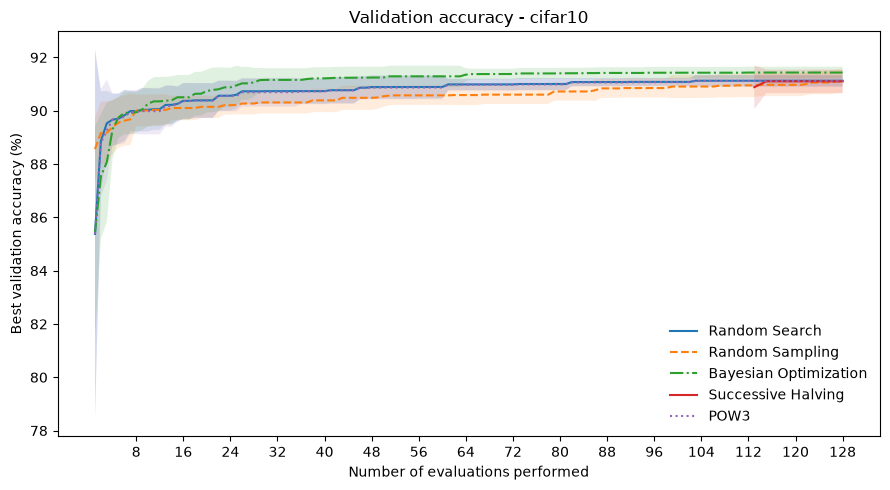

Random Search
Random Sampling
Bayesian Optimization
Successive Halving
POW3


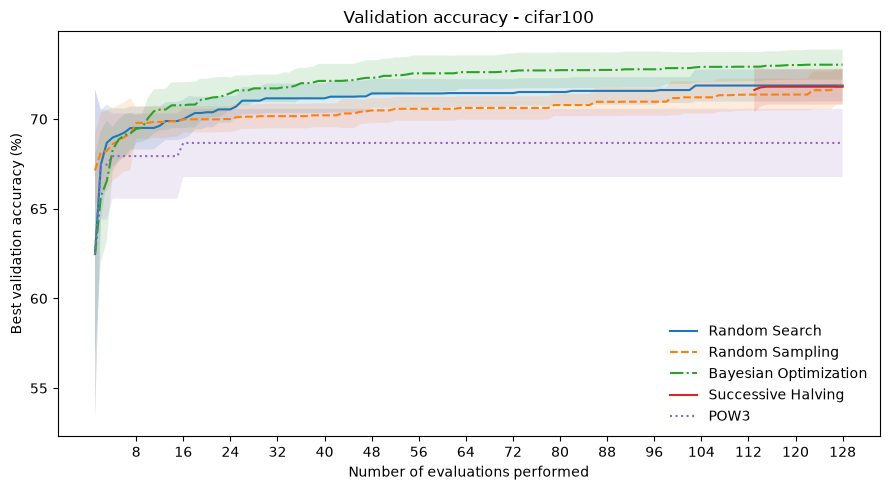

Random Search
Random Sampling
Bayesian Optimization
Successive Halving
POW3


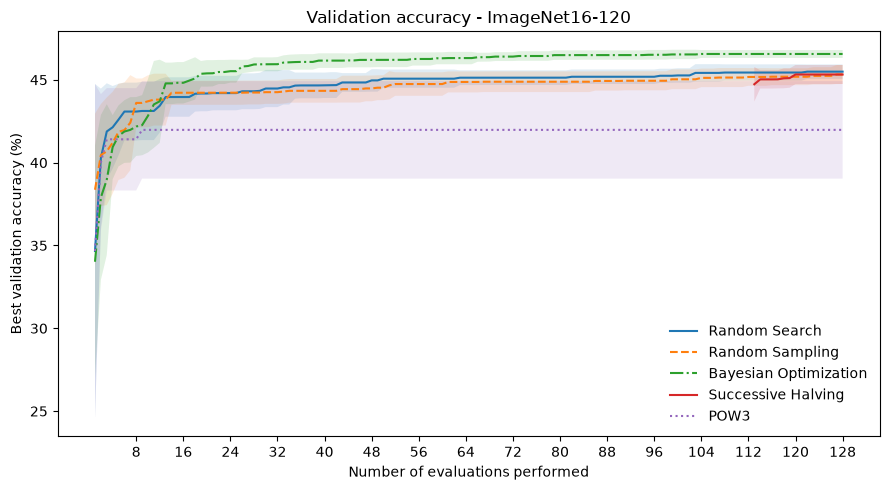

In [47]:
# table containing average over seeds
final_comparison = (
    summary_df
    .groupby(["method", "dataset"])
    .agg(
        mean_val=("val_accuracy", "mean"),
        std_val=("val_accuracy", "std"),
        mean_test=("test_accuracy", "mean"),
        std_test=("test_accuracy", "std"),
        mean_cost=("computation_cost", "mean"),
        std_cost=("computation_cost", "std"),
        mean_time=("runtime", "mean"),
        std_time=("runtime", "std")
    ).reset_index()
)

for col in ["mean_cost", "std_cost", "mean_time", "std_time"]: # minutes
    final_comparison[col] = (final_comparison[col] / 60) 

for col in ["mean_cost", "std_cost"]: # hours
    final_comparison[col] = (final_comparison[col] / 60) 

final_comparison["Validation-acc (%)"] = (
    final_comparison["mean_val"].map("{:.2f}".format)
 + " ± " +
 final_comparison["std_val"].map("{:.2f}".format)
)

final_comparison["Test-acc (%)"] = (
    final_comparison["mean_test"].map("{:.2f}".format)
 + " ± " +
 final_comparison["std_test"].map("{:.2f}".format)
)

final_comparison["Cost (hours)"] = (
    final_comparison["mean_cost"].map("{:.2f}".format)
 + " ± " +
 final_comparison["std_cost"].map("{:.2f}".format)
)

final_comparison["Python runtime (minutes)"] = (
    final_comparison["mean_time"].map("{:.2f}".format)
 + " ± " +
 final_comparison["std_time"].map("{:.2f}".format)
)

final_comparison_table = final_comparison[["method", "dataset", "Validation-acc (%)", "Test-acc (%)", "Cost (hours)", "Python runtime (minutes)" ]]

print(final_comparison_table)



# some of the historys have more than n_evals, that why we will take the last of each one
history_eval = (history_df
                .sort_values(["method", "dataset", "seed", "evaluation", "computation_cost"]) # done since we want the last done to be defintly the on that was performed last
                .groupby(
                    ["method", "dataset", "seed", "evaluation" ],
                    as_index=False)
                ).tail(1)

methods = ["Random Search", "Random Sampling", "Bayesian Optimization", "Successive Halving", "POW3"]
# methods = ["Random Search", "Random Sampling", "Bayesian Optimization", "POW3"]

styles = {
    "Random Search": {"linestyle": "-", "marker": None},
    "Random Sampling": {"linestyle": "--", "marker": None},
    "Bayesian Optimization": {"linestyle": "-.", "marker": None},
    "Successive Halving": {"linestyle": "-", "marker": None},
    "POW3": {"linestyle": ":", "marker": None}
} 





# creating figure for validation acc
for dataset in DATASETS:
    plt.figure(figsize=(9, 5))

    for method in methods:
        print(method)
        data = history_eval[
            (history_eval["dataset"] == dataset ) &
            (history_eval["method"] == method)
        ]

        stats = (
            data.groupby("evaluation")["best_val_accuracy"]
            .agg(["mean", "std"])
        )

        plt.plot(stats.index, stats["mean"], label=method, **styles[method])
        plt.fill_between(stats.index, stats["mean"] - stats["std"], stats["mean"] + stats["std"], alpha=0.14)

    plt.xlabel("Number of evaluations performed")
    plt.ylabel("Best validation accuracy (%)")
    plt.title(f"Validation accuracy - {dataset}")
    plt.legend(loc="lower right", frameon=False)
    plt.xticks(np.arange(8, 129, 8))
    # plt.xlim(1, 128)
    # plt.xlim(left=1)
    plt.tight_layout()
    plt.show()

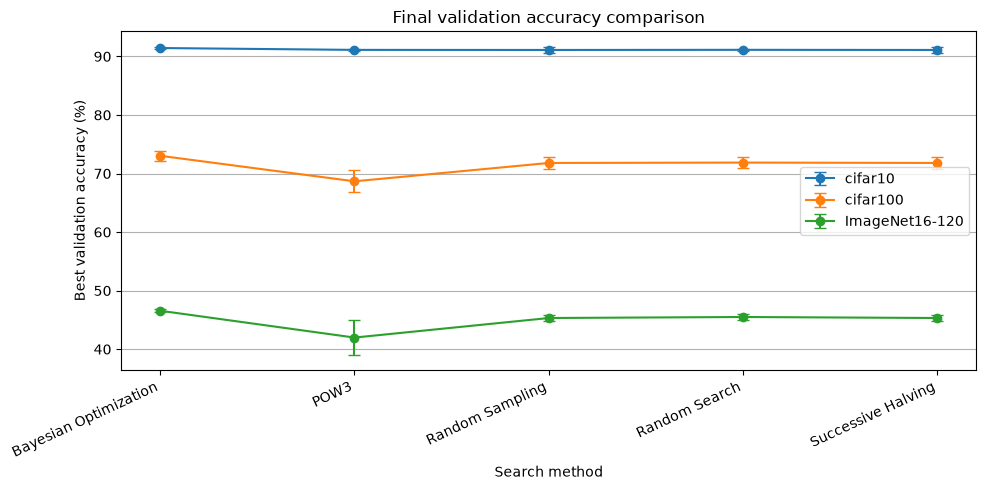

In [48]:
plt.figure(figsize=(10, 5))

for dataset in DATASETS:

    data = final_comparison[final_comparison["dataset"] == dataset]

    plt.errorbar(
        data["method"],
        data["mean_val"],
        yerr=data["std_val"],
        marker="o",
        capsize=4,
        label=dataset
    )

plt.ylabel("Best validation accuracy (%)")
plt.xlabel("Search method")
plt.title("Final validation accuracy comparison")
plt.xticks(rotation=25, ha="right")
ax = plt.gca()
ax.grid(True, axis='y')
plt.legend()
plt.tight_layout()
plt.show()

In [55]:
for dataset in DATASETS:
    plt.figure(figsize=(9, 5))
    i = 0
    for method in methods:
        i += 1
        print(method)
        data = history_eval[
            (history_eval["dataset"] == dataset ) &
            (history_eval["method"] == method)
        ]

        min_cost = data.groupby("seed")["computation_cost"].min().max()
        max_cost = data.groupby("seed")["computation_cost"].max().min()

        x_common = np.linspace(min_cost, max_cost, 200)
        print(data)
        for seed in data["seed"]:
            r

        
        

Random Search
             method  dataset  seed    idx  best_idx  evaluation  val_accuracy  \
0     Random Search  cifar10    20  13941   13941.0         1.0     88.996000   
1     Random Search  cifar10    20   4376    4376.0         2.0     89.726667   
2     Random Search  cifar10    20   4088    4376.0         3.0     88.538000   
3     Random Search  cifar10    20   7205    4376.0         4.0     80.554000   
4     Random Search  cifar10    20  13984    4376.0         5.0     53.957333   
...             ...      ...   ...    ...       ...         ...           ...   
1275  Random Search  cifar10    29   1656     168.0       124.0     90.890667   
1276  Random Search  cifar10    29   1161     168.0       125.0     89.004000   
1277  Random Search  cifar10    29   3229     168.0       126.0     86.820000   
1278  Random Search  cifar10    29   4916     168.0       127.0     89.402000   
1279  Random Search  cifar10    29  12126     168.0       128.0     89.156000   

      test_ac

<Figure size 900x500 with 0 Axes>

<Figure size 900x500 with 0 Axes>

<Figure size 900x500 with 0 Axes>